# plot_HS_TREFHT — CESM2 MA-GAUSS surface-temperature uncertainty partition

Python port that **merges** `plot_HS.m` (global + EU-band time series and
uncertainty partition) with `plot_regions_T.m` (per-IPCC-continental-region
partition), which in MATLAB ran back-to-back sharing the workspace
(`ta`, `b1`, `lat`, `lon`, `nums`, …).

The 7 MA-GAUSS strategies × 3 members of `TREFHT` are read from
`/Volumes/D_Visioni2/CESM2_MA/`, the SSP2-4.5 baseline is assembled from its
segment files, and the variance is partitioned into **scenario** (how much
cooling), **strategy** (where to inject), and **internal** (ensemble spread).

Region means are vectorised over the polygon mask (identical result to the
MATLAB per-month loop). All inputs are raw NetCDF / `AREA.nc` (external);
nothing is written except figures to `py_outputs/`.

In [1]:
import sys, os, glob
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, movmean, shaperead, inpolygon

fold = "/Volumes/D_Visioni2/CESM2_MA/MA_GAUSS/"
fold2 = "/Volumes/D_Visioni2/CESM2_MA/"
nam = "b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg."
exp = ["feedback_30N_30S", "feedback_15N_15S", "feedback_0N_1.0", "feedback_60N_60S_1.0",
       "SSP245-MA-GAUSS-DEFAULT", "SSP245-MA-GAUSS-LOWER-0.5", "SSP245-MA-GAUSS-LOWER-1.0"]
exp2 = ["1.0 above PI - 30-30", "1.0 above PI - 15-15", "1.0 above PI - EQ",
        "1.0 above PI - 60-60", "1.5 above PI - MS", "1.0 above PI - MS", "0.5 above PI - MS"]
ids = ".cam.h0."
var = "TREFHT"
ens = ["001", "002", "003"]
nums = [3, 3, 3, 3, 3, 3, 3]

## Read the 7×3 MA-GAUSS ensemble and the SSP2-4.5 baseline

In [2]:
ta = None
for ix, ex in enumerate(exp):
    for ie, en in enumerate(ens):
        f = sorted(glob.glob(f"{fold}{nam}{ex}.{en}{ids}{var}*.nc"))[0]
        t = mu.ncread(f, var)[:, :, 0:420].astype(np.float32)
        if ta is None:
            ta = np.empty(t.shape + (7, 3), dtype=np.float32)
        ta[:, :, :, ix, ie] = t
lat = mu.ncread(f, "lat").ravel(); lon = mu.ncread(f, "lon").ravel()

# baseline b1 (lon,lat,1020,3); member 2 only to 1008, member 3 segmented.
# Init with 0 (MATLAB auto-fills unassigned elements with 0): member 2's final
# year (months 1008:1020) is unassigned and must be 0, not NaN.
b1 = np.zeros(ta.shape[:2] + (1020, 3), dtype=np.float32)
b1[:, :, 0:600, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}{var}.201501-206412.nc", var)
b1[:, :, 600:1020, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}{var}.206501-209912.nc", var)
b1[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}{var}.201501-206412.nc", var)
b1[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}{var}.206501-209812.nc", var)
b1[:, :, 0:60, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}{var}.201501-201912.nc", var)
b1[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}{var}.202001-206912.nc", var)
b1[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}{var}.207001-209912.nc", var)

## Global and EU-band (lat 129:171) annual means

In [3]:
ww = np.cos(lat / 180 * np.pi)
lm, lM = 128, 171     # MATLAB 129:171 -> 0-based [128:171]
ta_zm = np.nanmean(ta, axis=0)      # (lat,420,7,3)
tab_zm = np.nanmean(b1, axis=0)     # (lat,1020,3)

ta_gm = (ta_zm * ww[:, None, None, None]).sum(0) / ww.sum()             # (420,7,3)
ta_reg = (ta_zm[lm:lM] * ww[lm:lM, None, None, None]).sum(0) / ww[lm:lM].sum()
tab_gm = (tab_zm * ww[:, None, None]).sum(0) / ww.sum()                  # (1020,3)
tab_reg = (tab_zm[lm:lM] * ww[lm:lM, None, None]).sum(0) / ww[lm:lM].sum()


def annual(x, n):    # monthly -> annual mean, MATLAB reshape(...,12,n,...) col-major
    sh = (12, n) + x.shape[1:]
    return np.reshape(x, sh, order="F").mean(axis=0)


ta_gm_y = annual(ta_gm, 35)                       # (35,7,3)
tab_gm_y = annual(tab_gm, 85)                      # (85,3)
ta_reg_mon = np.reshape(ta_reg, (12, 35, 7, 3), order="F")
ta_reg_y = ta_reg_mon[0:3].mean(0)                 # DJF (months 1:3)
tab_reg_mon = np.reshape(tab_reg, (12, 85, 3), order="F")
tab_reg_y = tab_reg_mon[0:3].mean(0)

## Variance partition helper (scenario / strategy / internal)

In [4]:
def partition(y):
    """y: (35, 7, 3) annual means. Returns (int_var, stra_var, sce_var) over time."""
    internal = y[:, 4, :]              # exp 5, all members
    strategy = y[:, [0, 1, 2, 3, 5], 0]  # exps 1-4,6 member 1
    scenario = y[:, 4:7, 0]            # exps 5-7 member 1
    iv = np.std(internal, axis=1, ddof=1) ** 2
    sv = np.std(strategy, axis=1, ddof=1) ** 2
    cv = np.std(scenario, axis=1, ddof=1) ** 2
    return iv, sv, cv

## Figure 1 — global & EU-band cooling and the global/EU partition

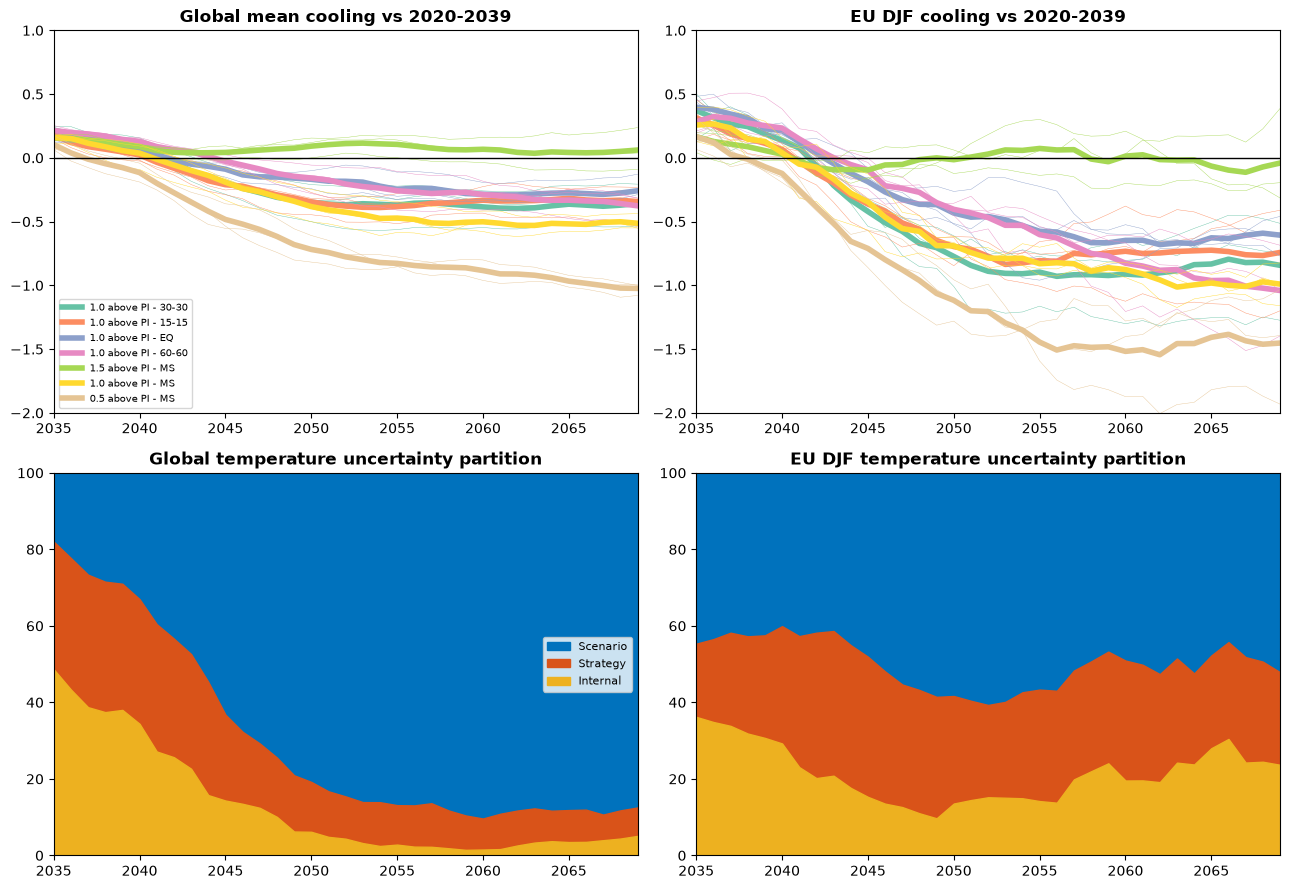

In [5]:
fc = brewermap(7, "Set2")
# MATLAB default area() color order (used for the variance-partition panels)
AREA_C = [(0, 0.4470, 0.7410), (0.8500, 0.3250, 0.0980), (0.9290, 0.6940, 0.1250)]
time = np.arange(2035, 2070)
ref = slice(5, 25)        # 2020-2039 reference, MATLAB 6:25


def cooling_panel(ax, y, yb, title):
    for ix in range(7):
        for ie in range(nums[ix]):
            ax.plot(time, movmean(y[:, ix, ie] - yb[ref, ie].mean(), 10), color=fc[ix], linewidth=.3)
        ax.plot(time, np.mean(movmean(y[:, ix, :] - yb[ref, :].mean(0), 10), axis=1),
                color=fc[ix], linewidth=4, label=exp2[ix])
    ax.plot([2035, 2070], [0, 0], "k", linewidth=1)
    ax.set_title(title, fontweight="bold"); ax.set_xlim(2035, 2069); ax.set_ylim(-2, 1)


def partition_panel(ax, y, title):
    iv, sv, cv = partition(y); tot = iv + sv + cv
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0], label="Scenario")
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1], label="Strategy")
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2], label="Internal")
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100); ax.set_title(title, fontweight="bold")


fig1, axs = plt.subplots(2, 2, figsize=(13, 9))
cooling_panel(axs[0, 0], ta_gm_y, tab_gm_y, "Global mean cooling vs 2020-2039")
axs[0, 0].legend(fontsize=7, loc="lower left")
cooling_panel(axs[0, 1], ta_reg_y, tab_reg_y, "EU DJF cooling vs 2020-2039")
partition_panel(axs[1, 0], ta_gm_y, "Global temperature uncertainty partition")
axs[1, 0].legend(fontsize=8, loc="center right")
partition_panel(axs[1, 1], ta_reg_y, "EU DJF temperature uncertainty partition")
fig1.tight_layout(); plt.show()

## Per-IPCC-continental-region partition (merged from plot_regions_T)
Area-weighted regional means using `AREA.nc`; vectorised over the polygon mask.

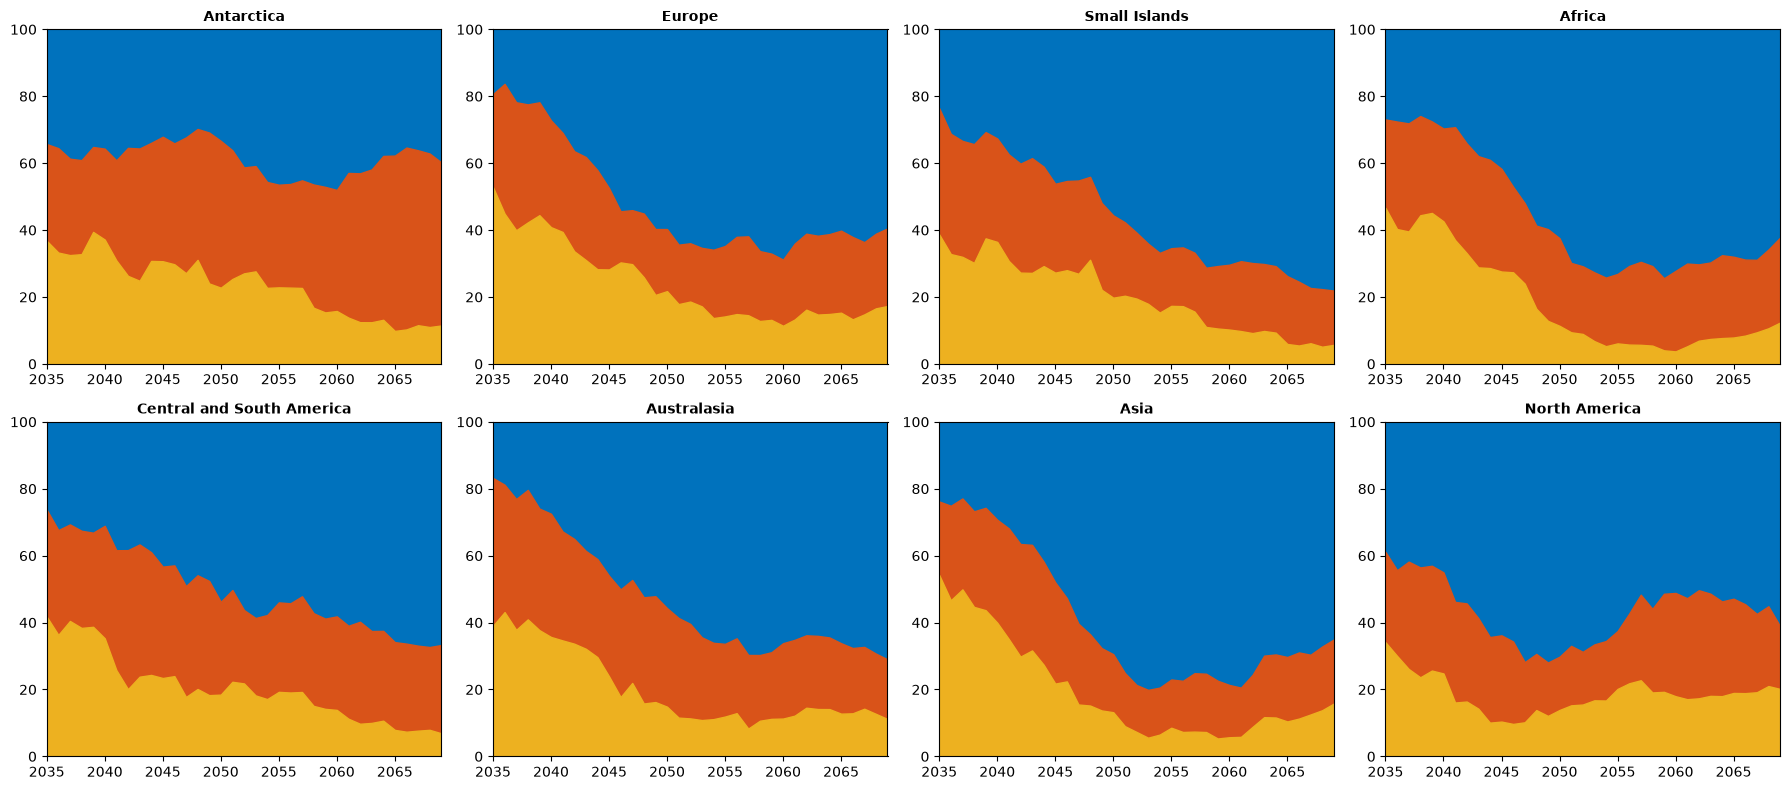

per-region mean (int,stra,sce) variance:
  Antarctica: [0.2242 0.3632 0.3974]
  Europe: [0.1278 0.1139 0.342 ]
  Small Islands: [0.0362 0.052  0.1509]
  Africa: [0.0342 0.0523 0.14  ]
  Central and South America: [0.0437 0.0745 0.1586]
  Australasia: [0.0603 0.0858 0.21  ]
  Asia: [0.0477 0.0695 0.2612]
  North America: [0.0737 0.0932 0.2745]


In [6]:
regions = shaperead("IPCC_WGII_continental_regions.shx")
latM, lonM = np.meshgrid(lat, lon - 180)
AA = np.nanmean(mu.ncread("AREA.nc", "AREA"), axis=2)    # (lon,lat)

fc7 = brewermap(7, "Set2")
fig2, axes = plt.subplots(2, 4, figsize=(18, 8))
region_var = {}
for f in range(8):
    ind = inpolygon(latM, lonM, regions[f].Y, regions[f].X)
    # vectorised regional mean: (npix, 420, 7, 3) -> (420,7,3)
    ta_reg_f = np.nanmean(ta[ind], axis=0)
    ta_reg_yf = np.reshape(ta_reg_f, (12, 35, 7, 3), order="F").mean(0)   # annual
    iv, sv, cv = partition(ta_reg_yf); tot = iv + sv + cv
    ax = axes.ravel()[f]
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0])
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1])
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2])
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100)
    ax.set_title(regions[f].Region, fontweight="bold", fontsize=10)
    region_var[regions[f].Region] = (float(np.nanmean(iv)), float(np.nanmean(sv)), float(np.nanmean(cv)))
fig2.tight_layout(); plt.show()
print("per-region mean (int,stra,sce) variance:")
for k, v in region_var.items():
    print(f"  {k}: {np.round(v,4)}")

In [7]:
os.makedirs("py_outputs", exist_ok=True)
fig1.savefig("py_outputs/HS_plot_TREFHT.png", dpi=300, bbox_inches="tight")
fig2.savefig("py_outputs/HS_plot_TREFHT_regions.png", dpi=300, bbox_inches="tight")
print("done")

done
